# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Цибух Андріана Тарасівна'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-33'      # напр. 'КН-31'
ВАРІАНТ =15     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 15 · Цибух Андріана Тарасівна, ШІ-33, «Карпатський дуб»
Підприємство «Карпатський дуб» виготовляє меблі. Одиниця виміру плану: шт./тиждень.

                   Крісло  Стілець  Табурет  Лава  ЗАПАС
Дубовий брус, м         5        3        3     1    613
Фанера, м²              2        5        6     6    316
Фурнітура, компл.       3        1        0     0   1035
Верстат, год            0        4        4     6    739
Лакування, год          2        2        2     6    810

                    Крісло  Стілець  Табурет  Лава
Прибуток з одиниці      64       58       34    63

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Дубовий брус, м
  ціна:   5.4 за одиницю
  обсяг:  до 354 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x₁ - випуск крісел, x₂ - випуск стільців, x₃ - випуск табуретів, x₄ - випуск лав.

Цільова функція: Z = 64·x₁ + 58·x₂ + 34·x₃ + 63·x₄ → max

Обмеження:
* 5·x₁ + 3·x₂ + 3·x₃ + 1·x₄ ≤ 613   (дубовий брус, м)
* 2·x₁ + 5·x₂ + 6·x₃ + 6·x₄ ≤ 316   (фанера, м²)
* 3·x₁ + 1·x₂ + 0·x₃ + 0·x₄ ≤ 1035  (фурнітура, компл.)
* 0·x₁ + 4·x₂ + 4·x₃ + 6·x₄ ≤ 739   (верстат, год)
* 2·x₁ + 2·x₂ + 2·x₃ + 6·x₄ ≤ 810   (лакування, год)


Невід'ємність: x₁, x₂, x₃, x₄ ≥ 0.


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**
Запас - це параметр, бо на момент планування він заданий ззовні: брус і фанеру
вже закуплено, верстат і лакувальну ділянку не можна збільшити. Ми обираємо лише скільки чого
виготовити. Якби ресурс можна було докупити в будь-якій кількості, запас став би змінною:
перше обмеження мало б вигляд 5·x₁ + 3·x₂ + 3·x₃ + 1·x₄ ≤ 613 + y, y ≥ 0, а в цільовій функції
з'явився б доданок −ціна·y. Тоді задача перестала б бути «як найкраще використати наявне»
і стала б «скільки ще купити».

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [120.0714, 0, 0, 12.6429]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 8481.0714             # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [120.0714, 0, 0, 12.6429] | прибуток 8481.0714


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c), method='highs')
assert res.status == 0, res.message

план = res.x
прибуток = -res.fun
shadow  = np.round(-res.ineqlin.marginals, 6) + 0.0  # тіньові ціни ресурсів
reduced = np.round(-res.lower.marginals, 6) + 0.0    # зведені вартості виробів

print('linprog: план', np.round(план, 4), '| прибуток %.4f' % прибуток)
print('тіньові ціни:  ', {r: float(s) for r, s in zip(ресурси, shadow)})
print('зведені вартості:', {v: float(s) for v, s in zip(вироби, reduced)})

# те саме через pulp
if ПУЛП:
    m = pulp.LpProblem('mebli', pulp.LpMaximize)
    xv = [pulp.LpVariable('x%d' % (j + 1), lowBound=0) for j in range(len(c))]
    m += pulp.lpSum(c[j] * xv[j] for j in range(len(c)))
    for i in range(len(b)):
        m += pulp.lpSum(A[i, j] * xv[j] for j in range(len(c))) <= b[i], 'r%d' % i
    m.solve(pulp.PULP_CBC_CMD(msg=0))
    print('pulp   : план', [round(v.value(), 4) for v in xv], '| прибуток %.4f' % pulp.value(m.objective))


linprog: план [120.0714   0.       0.      12.6429] | прибуток 8481.0714
тіньові ціни:   {'Дубовий брус, м': 9.214286, 'Фанера, м²': 8.964286, 'Фурнітура, компл.': 0.0, 'Верстат, год': 0.0, 'Лакування, год': 0.0}
зведені вартості: {'Крісло': 0.0, 'Стілець': -14.464286, 'Табурет': -47.428571, 'Лава': 0.0}
pulp   : план [120.0714, 0.0, 0.0, 12.6429] | прибуток 8481.0715


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Дубовий брус, м | 613.0000 | 9.2143 | 613 | 177 | 560.3333 |
| Фанера, м² | 316.0000 | 8.9643 | 316 | 494 | 70.8 |
| Фурнітура, компл. | 360.2143 | 0 | 1035 | 1E+30 | 674.7857 |
| Верстат, год | 75.8571 | 0 | 739 | 1E+30 | 663.1429 |
| Лакування, год | 316.0000 | 0 | 810 | 1E+30 | 494 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**
У дефіциті два ресурси - дубовий брус і фанера. Ознака подвійна, і обидві умови мають виконуватися
одночасно: Кінцеве значення дорівнює Правій частині (613 = 613 і 316 = 316) і тіньова ціна строго
більша за нуль (9.2143 та 8.9643). Решта три ресурси в надлишку: фурнітури лишається 674.79, верстата -
663.14, лакування - 494 (тут кінцеве значення менше за праву частину), тіньова ціна нульова, а допустиме
збільшення дорівнює 1E+30, тобто «нескінченність»: скільки цього запасу не додавай, план не зміниться.
Лакування варто відзначити окремо: його кінцеве значення 316 збігається з фанерою, але це збіг
цифр (коефіцієнти цих двох рядків при Кріслі й Лаві однакові), а не дефіцит - права частина 810.
Отже вузьке місце виробництва - брус і фанера, а розширювати верстат, фурнітуру чи лакування зараз
немає сенсу.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крісло | 120.0714 | 0 | 64 | 31.1538 | 251 |
| Стілець | 0.0000 | −14.4643 | 58 | 14.4643 | 1E+30 |
| Табурет | 0.0000 | −47.4286 | 34 | 47.4286 | 1E+30 |
| Лава | 12.6429 | 0 | 63 | 21.3158 | 129 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Не виробляються два вироби: Стілець і Табурет (кінцеве значення 0 в обох). Ближчий до входження в план -
Стілець: його зведена вартість −14.4643, тобто примусовий випуск однієї штуки зменшив би загальний
прибуток на 14.46, бо ресурси (брус і фанера) вигідніше віддати Кріслам й Лавам. Щоб Стілець увійшов у план,
прибуток з його одиниці має зрости з 58 приблизно до 58 + 14.4643 = 72.4643. Це число береться зі стовпця
«Зведена вартість» блоку «Змінні» звіту; воно ж стоїть у стовпці «Допустиме збільшення» цільового
коефіцієнта (14.4643) - для невиробленого виробу ці дві величини за модулем збігаються. Для Табурета
відповідне зростання більше: з 34 до 34 + 47.4286 = 81.4286, тож він від плану ще далі.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# ВАШ КОД
def розвязати(bb, цілі=False):
    r = linprog(-c, A_ub=A, b_ub=bb, bounds=[(0, None)] * len(c), method='highs',
                integrality=np.ones(len(c)) if цілі else None)
    return -r.fun, r.x

i_res = int(np.argmax(shadow))              # ресурс із найбільшою тіньовою ціною
bb = b + np.eye(len(b))[i_res]              # +1 одиниця саме цього ресурсу
z1, x1 = розвязати(bb)
приріст = z1 - прибуток

print('найдорожчий ресурс:', ресурси[i_res], '| тіньова ціна зі звіту: %.4f' % shadow[i_res])
print('прибуток: %.4f -> %.4f' % (прибуток, z1))
print('приріст за +1 одиницю:    %.4f' % приріст)
print('різниця з тіньовою ціною: %.2e' % (приріст - shadow[i_res]))
print('план змінився:', np.round(план, 4), '->', np.round(x1, 4))

найдорожчий ресурс: Дубовий брус, м | тіньова ціна зі звіту: 9.2143
прибуток: 8481.0714 -> 8490.2857
приріст за +1 одиницю:    9.2143
різниця з тіньовою ціною: -2.86e-07
план змінився: [120.0714   0.       0.      12.6429] -> [120.2857   0.       0.      12.5714]


**Відповідь 5.1:** *(приріст прибутку = ..., тіньова ціна зі звіту = ..., збігаються?)*

Приріст прибутку = 8490.2857 − 8481.0714 = 9.2143, тіньова ціна зі звіту = 9.2143, збігаються. План при цьому перебудувався: Крісла додалося на 0.2143, а Лав зменшилося на 0.0714 - додаткова одиниця бруса не додає прибутку сама по собі, вона дозволяє перекласти план на вигідніший склад виробів.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

приріст дорівнює тіньовій ціні 9.2143 на перших 177 кроках
межа діапазону: запас Дубовий брус, м від 613 до 790
приріст після зламу: 0.0000


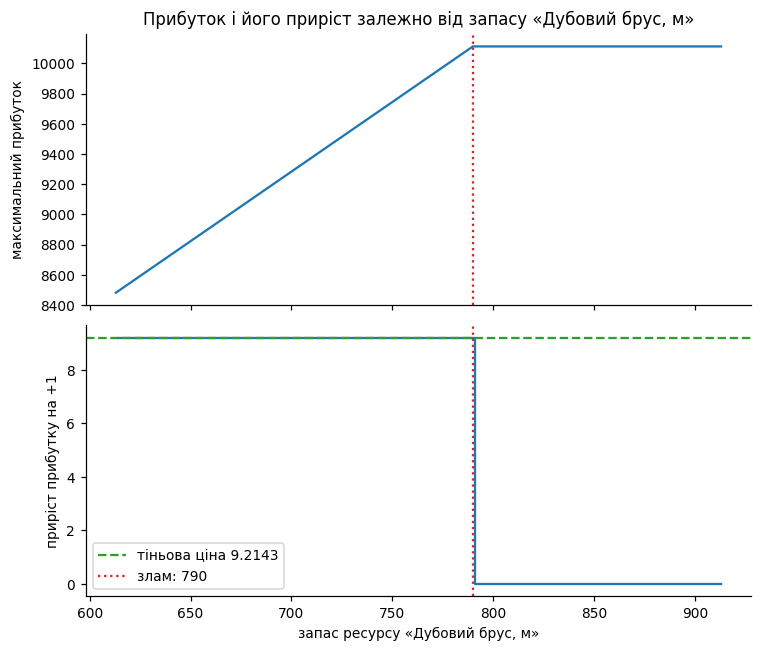

In [8]:
# ВАШ КОД
крок = np.arange(0, 301)                                   # скільки одиниць додано до запасу
запаси = b[i_res] + крок
прибутки = np.array([розвязати(b + k * np.eye(len(b))[i_res])[0] for k in крок])
прирости = np.diff(прибутки)                               # приріст прибутку за кожну наступну одиницю

повний = np.isclose(прирости, shadow[i_res], atol=1e-6)    # де приріст ще дорівнює тіньовій ціні
q_межа = int(np.argmin(повний))                            # перший крок, де приріст упав
print('приріст дорівнює тіньовій ціні %.4f на перших %d кроках' % (shadow[i_res], q_межа))
print('межа діапазону: запас %s від %d до %d' % (ресурси[i_res], b[i_res], b[i_res] + q_межа))
print('приріст після зламу: %.4f' % прирости[q_межа])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax1.plot(запаси, прибутки)
ax1.axvline(b[i_res] + q_межа, color='tab:red', ls=':')
ax1.set_ylabel('максимальний прибуток')
ax1.set_title('Прибуток і його приріст залежно від запасу «%s»' % ресурси[i_res])
ax2.step(запаси[1:], прирости, where='post')
ax2.axhline(shadow[i_res], color='tab:green', ls='--', label='тіньова ціна %.4f' % shadow[i_res])
ax2.axvline(b[i_res] + q_межа, color='tab:red', ls=':', label='злам: %d' % (b[i_res] + q_межа))
ax2.set_xlabel('запас ресурсу «%s»' % ресурси[i_res])
ax2.set_ylabel('приріст прибутку на +1')
ax2.legend()
plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

Запас бруса можна збільшити на 177 одиниць (з 613 до 790): на цьому проміжку приріст
прибутку лежить точно на лінії тіньової ціни 9.2143, а на наступній одиниці падає до нуля - на нижньому графіку
видно горизонтальну ділянку й різкий злам, на верхньому - пряму, що переходить у полицю (прибуток 10112).
Знайдена межа збігається з «допустимим збільшенням» зі звіту Excel (177).

Чому межа саме така: кожна додаткова одиниця бруса додає 0.2143 Крісла й віднімає 0.0714 Лави. Лави в плані 12.6429, тож вони закінчаться за
12.6429 / 0.0714 = 177 кроків. Далі випускається 158 самих Крісел, брус перестає бути дефіцитним,
і його тіньова ціна стає нульовою.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
# ВАШ КОД
k = V['ресурс_пропозиції']; ціна = V['ціна_пропозиції']; обсяг = V['обсяг_пропозиції']
print('пропозиція: %s, ціна %.1f, до %d од.; тіньова ціна %.4f' % (ресурси[k], ціна, обсяг, shadow[k]))

q_всі = np.arange(0, обсяг + 1)
z_q = np.array([розвязати(b + q * np.eye(len(b))[k])[0] for q in q_всі])
виграш = z_q - прибуток                     # приріст прибутку від закупівлі q одиниць
чистий = виграш - ціна * q_всі              # мінус гроші постачальнику
q_злам = int(np.argmin(np.isclose(np.diff(z_q), shadow[k], atol=1e-6)))
q_опт = int(np.argmax(чистий))

обрані = sorted({1, 100, q_злам, обсяг, q_опт})
табл = pd.DataFrame({'куплено': обрані,
                     'приріст прибутку': [виграш[q] for q in обрані],
                     'вартість': [ціна * q for q in обрані],
                     'чистий результат': [чистий[q] for q in обрані]}).round(4)
print(табл.to_string(index=False))
print('\nмежа дії тіньової ціни: %d од.; оптимум закупівлі: %d од.' % (q_злам, q_опт))
print('виграш від закупівлі оптимальної кількості: %.4f' % чистий[q_опт])

пропозиція: Дубовий брус, м, ціна 5.4, до 354 од.; тіньова ціна 9.2143
 куплено  приріст прибутку  вартість  чистий результат
       1            9.2143       5.4            3.8143
     100          921.4286     540.0          381.4286
     177         1630.9286     955.8          675.1286
     354         1630.9286    1911.6         -280.6714

межа дії тіньової ціни: 177 од.; оптимум закупівлі: 177 од.
виграш від закупівлі оптимальної кількості: 675.1286


**Відповідь 6.1:**

* Брати чи ні і чому: брати. Ціна постачальника 5.4 за одиницю бруса менша за тіньову ціну 9.2143: кожна
  куплена одиниця приносить 9.2143 прибутку й коштує 5.4, чистий виграш 3.8143 за одиницю.
* Скільки одиниць має сенс купити і чому не більше: 177, а не всі 354. Тіньова ціна чинна лише в межах
  «допустимого збільшення» 177; далі приріст прибутку дорівнює нулю (прибуток стоїть на 10112), тож за решту
  177 одиниць довелося б платити повну ціну 5.4 і нічого не отримати.
* Очікуваний виграш: 177 · (9.2143 − 5.4) = 177 · 3.8143 ≈ 675.13 (приріст прибутку 1630.93 мінус
  витрати 955.80).
* Перевірка прямим розв'язанням дала: при запасі бруса 613 + 177 = 790 прибуток 10112, приріст 1630.9286,
  чистий результат 675.1286 - збіг. Для порівняння: купівля всіх 354 одиниць дала б чистий результат
  -280.67, тобто пропозицію не можна брати цілком.


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
# ВАШ КОД
витрати = A @ план
ненульових = int(np.sum(план > 1e-6))
звязних = int(np.sum(np.isclose(витрати, b, atol=1e-6)))
print(pd.DataFrame({'витрачено': витрати, 'запас': b, 'залишок': b - витрати}, index=ресурси).round(4))


                   витрачено   запас   залишок
Дубовий брус, м     613.0000   613.0    0.0000
Фанера, м²          316.0000   316.0    0.0000
Фурнітура, компл.   360.2143  1035.0  674.7857
Верстат, год         75.8571   739.0  663.1429
Лакування, год      316.0000   810.0  494.0000


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)*

Ненульових змінних 2 (Крісло й Лава), зв'язних обмежень теж 2 (брус і фанера) - числа
збіглися. Це не випадковість: оптимум лежить у вершині допустимої області, а вершина в просторі чотирьох
змінних задається чотирма активними умовами - тут це x₂ = 0, x₃ = 0 і два зв'язні ресурси, разом 4 за кількості
змінних 4. Розбіжність означала б виродженість: у вершині перетинається більше обмежень, ніж треба для
її визначення. Тоді тіньова ціна перестає бути однозначною, допустиме збільшення може стати нульовим, а різні
розв'язувачі законно повертають різні набори тіньових цін при однаковому плані.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# ВАШ КОД
x_низ = np.floor(план + 1e-9)               # округлення вниз
x_найбл = np.round(план)                    # округлення до найближчого
z_ц, x_ц = розвязати(b, цілі=True)          # справжній цілочисельний оптимум
x_ц = np.round(x_ц)

def оцінка(xx):
    return bool(np.all(A @ xx <= b + 1e-9)), float(c @ xx)

рядки = []
for назва, xx in [('без умови цілочисельності', план), ('округлений вниз', x_низ),
                  ('округлений до найближчого', x_найбл), ('цілочисельний оптимум', x_ц)]:
    ok, z = оцінка(xx)
    рядки.append([назва] + list(np.round(xx, 4)) + [round(z, 4), 'так' if ok else 'НІ'])
print(pd.DataFrame(рядки, columns=['варіант'] + вироби + ['прибуток', 'допустимий']).to_string(index=False))

перевитрата = A @ x_найбл - b
print('\nокруглення до найближчого, перевитрата ресурсів:',
      {ресурси[i]: float(перевитрата[i]) for i in range(len(b)) if перевитрата[i] > 1e-9})

# Чи надійне «округлення вниз» взагалі? Зсуваємо запас другого за цінністю ресурсу й порівнюємо
j = int(np.argsort(shadow)[-2])
програш = []
for q in range(0, 120):
    bb = b + q * np.eye(len(b))[j]
    xf = np.floor(розвязати(bb)[1] + 1e-9)
    програш.append(розвязати(bb, цілі=True)[0] - c @ xf)
програш = np.array(програш)
print('\nекскурс: запас «%s» від %d до %d:' % (ресурси[j], b[j], b[j] + 119))
print('  округлення вниз не оптимальне у %d із %d випадків, найбільша втрата прибутку %.1f' %
      (np.sum(програш > 1e-6), len(програш), програш.max()))
print('  оцінки: %.2f (округлений) <= %.2f (цілий оптимум) <= %.2f (дробовий)' % (оцінка(x_низ)[1], z_ц, прибуток))

                  варіант   Крісло  Стілець  Табурет    Лава  прибуток допустимий
без умови цілочисельності 120.0714      0.0      0.0 12.6429 8481.0714        так
          округлений вниз 120.0000      0.0      0.0 12.0000 8436.0000        так
округлений до найближчого 120.0000      0.0      0.0 13.0000 8499.0000         НІ
    цілочисельний оптимум 120.0000      0.0      0.0 12.0000 8436.0000        так

округлення до найближчого, перевитрата ресурсів: {'Фанера, м²': 2.0}

екскурс: запас «Фанера, м²» від 316 до 435:
  округлення вниз не оптимальне у 61 із 120 випадків, найбільша втрата прибутку 64.0
  оцінки: 8436.00 (округлений) <= 8436.00 (цілий оптимум) <= 8481.07 (дробовий)


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | (120.0714; 0; 0; 12.6429) | 8481.0714 | так |
| округлений вниз | (120; 0; 0; 12) | 8436 | так |
| округлений до найближчого | (120; 0; 0; 13) | 8499 | ні (фанери 318 при запасі 316) |
| цілочисельний оптимум | (120; 0; 0; 12) | 8436 | так |

**Висновок:** Просто округлювати не можна. Округлення до найближчого дає план (120; 0; 0; 13), який
недопустимий: на нього потрібно 318 м² фанери при запасі 316 (його «прибуток» 8499 більший за дробовий
оптимум 8481 - типова ознака недопустимого плану). Округлення вниз у ресурсних задачах із невід'ємними
витратами завжди допустиме, але не гарантує оптимальності. У моєму варіанті воно випадково збіглося з
цілочисельним оптимумом (8436), проте якщо трохи змінити запас фанери, воно програє в 61 із 120 випадків
(до 64 одиниць прибутку на одному плані). Загальне співвідношення:
округлений ≤ цілочисельний оптимум ≤ дробовий, тут 8436 ≤ 8436 ≤ 8481.07.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# ВАШ КОД — впишіть свої дані
постачальники = ['Цумань', 'Біла Церква', 'Умань']
споживачі     = ['Апостолове', 'Ніжин', 'Дніпро', 'Рівне']
D = np.array([[800, 590, 940, 110],
              [450, 210, 440, 330],
              [470, 350, 520, 430]], dtype=float)
запас = [45, 35, 40]          # 3 числа
попит = [25, 30, 35, 30]      # 4 числа

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Апостолове,Ніжин,Дніпро,Рівне
Цумань,800.0,590.0,940.0,110.0
Біла Церква,450.0,210.0,440.0,330.0
Умань,470.0,350.0,520.0,430.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# ВАШ КОД — розв'язок 1 (pulp)
assert ПУЛП, 'для цього розв\'язку потрібен pulp'
m_, n_ = D.shape
prob = pulp.LpProblem('transport', pulp.LpMinimize)
xt = [[pulp.LpVariable('x_%d_%d' % (i, j), lowBound=0) for j in range(n_)] for i in range(m_)]
prob += pulp.lpSum(D[i, j] * xt[i][j] for i in range(m_) for j in range(n_))
for i in range(m_):
    prob += pulp.lpSum(xt[i]) == запас[i], 'supply_%d' % i
for j in range(n_):
    prob += pulp.lpSum(xt[i][j] for i in range(m_)) == попит[j], 'demand_%d' % j
prob.solve(pulp.PULP_CBC_CMD(msg=0))

план1 = np.array([[xt[i][j].value() for j in range(n_)] for i in range(m_)])
вартість1 = pulp.value(prob.objective)
ціни1 = np.array([prob.constraints['supply_%d' % i].pi for i in range(m_)] +
                 [prob.constraints['demand_%d' % j].pi for j in range(n_)])
print('pulp: сумарна вартість =', вартість1)
print(pd.DataFrame(план1, index=постачальники, columns=споживачі).astype(int))
print('тіньові ціни (запаси, потім попит):', ціни1)

pulp: сумарна вартість = 43650.0
             Апостолове  Ніжин  Дніпро  Рівне
Цумань                0     15       0     30
Біла Церква           0     15      20      0
Умань                25      0      15      0
тіньові ціни (запаси, потім попит): [ 590.  210.  290.  180.    0.  230. -480.]


In [15]:
# ВАШ КОД — розв'язок 2 (scipy.optimize.linprog)
A_eq = np.zeros((m_ + n_, m_ * n_))
for i in range(m_):
    for j in range(n_):
        A_eq[i, i * n_ + j] = 1          # рядки 0..2: сума перевезень з постачальника i
        A_eq[m_ + j, i * n_ + j] = 1     # рядки 3..6: сума перевезень до споживача j
b_eq = list(запас) + list(попит)
res_tr = linprog(D.ravel(), A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method='highs')
assert res_tr.status == 0, res_tr.message

план2 = res_tr.x.reshape(m_, n_)
вартість2 = res_tr.fun
ціни2 = np.array(res_tr.eqlin.marginals)
print('linprog: сумарна вартість =', вартість2)
print(pd.DataFrame(план2, index=постачальники, columns=споживачі).round(4))
print('тіньові ціни (запаси, потім попит):', ціни2)

linprog: сумарна вартість = 43650.0
             Апостолове  Ніжин  Дніпро  Рівне
Цумань              0.0   15.0     0.0   30.0
Біла Церква         0.0   15.0    20.0    0.0
Умань              25.0    0.0    15.0    0.0
тіньові ціни (запаси, потім попит): [  -0. -380. -300.  770.  590.  820.  110.]


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
# ВАШ КОД — порівняння
assert np.isclose(вартість1, вартість2) and np.allclose(план1, план2, atol=1e-6), 'плани чи вартість розійшлися'
імена = ['запас: ' + p for p in постачальники] + ['попит: ' + s for s in споживачі]
порівняння = pd.DataFrame({'pulp': ціни1, 'scipy': ціни2, 'scipy − pulp': ціни2 - ціни1}, index=імена)
print(порівняння.round(4))
print('\nрізниця для постачальників:', set(np.round((ціни2 - ціни1)[:m_], 6)))
print('різниця для споживачів:    ', set(np.round((ціни2 - ціни1)[m_:], 6)))
u1, v1, u2, v2 = ціни1[:m_], ціни1[m_:], ціни2[:m_], ціни2[m_:]
print('\nінваріанти (однакові в обох розв\'язувачах):')
print('  u_Цумань − u_Умань:  pulp %.0f | scipy %.0f' % (u1[0] - u1[2], u2[0] - u2[2]))
print('  v_Дніпро − v_Рівне:  pulp %.0f | scipy %.0f' % (v1[2] - v1[3], v2[2] - v2[3]))
print('  u_i + v_j збігаються для всіх пар:', np.allclose(u1[:, None] + v1[None, :], u2[:, None] + v2[None, :]))
print('ранг матриці обмежень: %d (обмежень %d)' % (np.linalg.matrix_rank(A_eq), A_eq.shape[0]))

                     pulp  scipy  scipy − pulp
запас: Цумань       590.0   -0.0        -590.0
запас: Біла Церква  210.0 -380.0        -590.0
запас: Умань        290.0 -300.0        -590.0
попит: Апостолове   180.0  770.0         590.0
попит: Ніжин          0.0  590.0         590.0
попит: Дніпро       230.0  820.0         590.0
попит: Рівне       -480.0  110.0         590.0

різниця для постачальників: {np.float64(-590.0)}
різниця для споживачів:     {np.float64(590.0)}

інваріанти (однакові в обох розв'язувачах):
  u_Цумань − u_Умань:  pulp 300 | scipy 300
  v_Дніпро − v_Рівне:  pulp 710 | scipy 710
  u_i + v_j збігаються для всіх пар: True
ранг матриці обмежень: 6 (обмежень 7)


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова - 43650, плани перевезень теж збіглися повністю.
* Тіньові ціни збіглися чи ні: ні - не збігся жоден із семи чисел (pulp: 590, 210, 290 для постачальників і
  180, 0, 230, −480 для споживачів; scipy: 0, −380, −300 і 770, 590, 820, 110).
* Яку закономірність ви побачили в різниці: різниця scipy - pulp для всіх трьох постачальників дорівнює
  −590, а для всіх чотирьох споживачів +590. Тобто один набір отримується з іншого заміною
  uᵢ → uᵢ − k, vⱼ → vⱼ + k при k = 590, і сума uᵢ + vⱼ для будь-якої пари не змінюється.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: причина - баланс
  (120 = 120). Сума трьох рівнянь постачальників тотожна сумі чотирьох рівнянь споживачів, одне
  обмеження лінійно залежне, ранг матриці дорівнює 6, а не 7. Тому двоїсті змінні визначені лише з точністю
  до адитивної константи, і кожен розв'язувач нормує її по-своєму. Абсолютні тіньові ціни читати не можна:
  «запас у Цумані вартий 590» на іншій бібліотеці стає «0». Змістовні лише різниці (u_Цумань − u_Умань = 300,
  v_Дніпро − v_Рівне = 710 в обох) і суми uᵢ + vⱼ, з яких рахується оцінка маршруту dᵢⱼ − uᵢ − vⱼ.
  Обидві відповіді правильні - вони різні представники однієї множини оптимальних двоїстих розв'язків.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# ВАШ КОД
ненульових_тр = int(np.sum(план2 > 1e-6))
витрати_тр = A_eq @ res_tr.x
звязних_тр = int(np.sum(np.isclose(витрати_тр, b_eq, atol=1e-6)))
ранг = int(np.linalg.matrix_rank(A_eq))
print('ненульових перевезень: %d | зв\'язних обмежень: %d з %d | ранг матриці: %d | m + n − 1 = %d' %
      (ненульових_тр, звязних_тр, A_eq.shape[0], ранг, m_ + n_ - 1))

ненульових перевезень: 6 | зв'язних обмежень: 7 з 7 | ранг матриці: 6 | m + n − 1 = 6


**Відповідь 11.1:**

* Ненульових перевезень: 6.
* Зв'язних обмежень: 7 із 7, ранг матриці обмежень 6.
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: вони записані рівностями. «Відправити
  з Цумані менше за 45» означало б залишок на складі, «привезти до Рівного менше за 30» - необслуговуваного
  клієнта, а модель цього не допускає. Слеку тут не існує в принципі, тому підрахунок зв'язних обмежень
  нічого не повідомляє: відповідь 7 відома ще до розв'язання.
* На скільки ненульових перевезень менше і чому саме на стільки: на одне, 3 + 4 − 1 = 6. Через баланс
  одне рівняння залежне, ранг матриці дорівнює 6, а базис опорного плану транспортної задачі містить рівно
  стільки клітинок. Тому перевірка «ненульових = зв'язних» з етапу 7 тут не працює: вона спиралася на
  незалежність обмежень і на те, що зайві обмеження неактивні, а в збалансованій транспортній задачі
  обидва припущення хибні.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

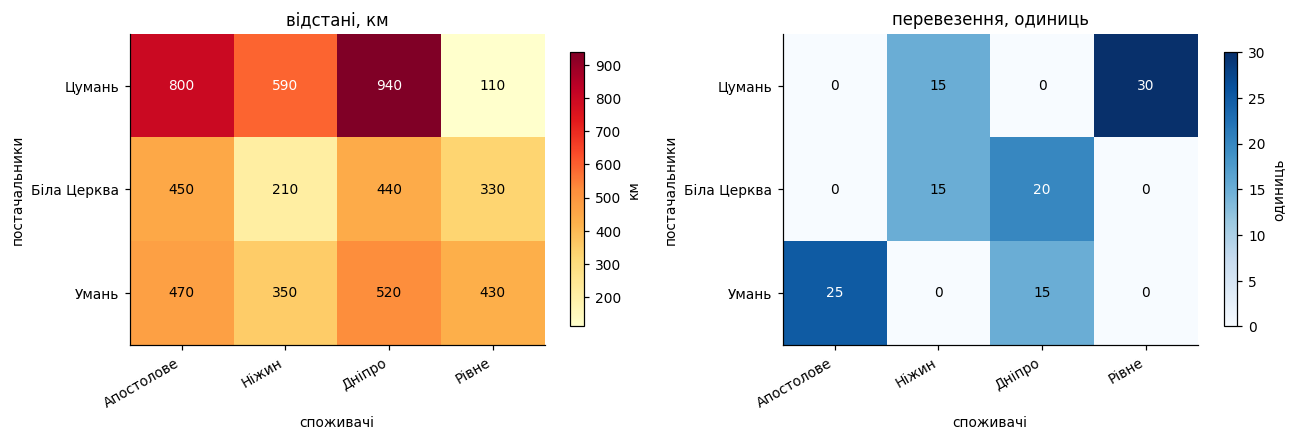

In [18]:
# ВАШ КОД
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, M, назва, cmap, lab in [(axes[0], D, 'відстані, км', 'YlOrRd', 'км'),
                                (axes[1], план2, 'перевезення, одиниць', 'Blues', 'одиниць')]:
    im = ax.imshow(M, cmap=cmap)
    ax.set_xticks(range(n_)); ax.set_xticklabels(споживачі, rotation=30, ha='right')
    ax.set_yticks(range(m_)); ax.set_yticklabels(постачальники)
    ax.set_xlabel('споживачі'); ax.set_ylabel('постачальники'); ax.set_title(назва)
    for i in range(m_):
        for j in range(n_):
            val = M[i, j]
            ax.text(j, i, '%d' % round(val), ha='center', va='center', fontsize=9,
                    color='white' if val > 0.6 * M.max() else 'black')
    fig.colorbar(im, ax=ax, label=lab, shrink=0.85)
plt.tight_layout()
plt.show()

**Висновок:** *(одне речення про те, що видно на теплових картах)* Оптимальний план тяжіє до коротких клітинок матриці відстаней (Цумань → Рівне, 110 км, уся
потреба 30), але не буквально до «найближчого»: Апостолове обслуговує Умань (470 км), хоча з Білої Церкви
ближче (450 км) - запаси Білої Церкви пішли на Ніжин і Дніпро; карти показують компроміс між відстанню і
рамками запасів та попиту.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [19]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'ні',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'ні',
    'етап 6, рішення про закупівлю':        'код, перевірено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'Прочитала згенерований код і звірила його з моделлю з етапу 1: матриця A, вектори c і b у linprog відповідають моїм обмеженням, знак -c і -res.fun врахований. Запустила Пошук рішення в Excel, порівняла план і звіт про стійкість із результатами Python — збіглися. Перевірила тіньову ціну бруса вручну: запас +1 дав приріст 9.2143, а межу 177 побачила на графіку. У транспортній задачі звірила відстані, перевірила баланс 120=120, зрозуміла, чому тіньові ціни зсунуті на константу (ранг 6 із 7).'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [20]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Цибух Андріана Тарасівна
інструменти:                               Gemini
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     ні
етап 6, рішення про закупівлю:             код, перевірено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Прочитала згенерований код і звірила його з моделлю з етапу 1: матриця A, вектори c і b у linprog відповідають моїм обмеженням, знак -c і -res.fun врахований. Запустила Пошук рішення в Excel, порівняла план і звіт про стійкість із результатами Python — збіглися. Перевірила тіньову ціну бруса вручну: запас

---
# Крок 13. Фінальна самоперевірка

In [21]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
